In [27]:
import os
import glob
from collections import Counter

import cv2
import numpy as np
import matplotlib.pyplot as plt
from joblib import dump, load

from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

In [8]:
DATASET_DIR = "fire_dataset"   # پوشه‌ی دیتاست (کنار همین نوت‌بوک)
TEST_DIR    = "test"           # پوشه‌ی عکس‌های جدید برای تست
MODEL_FILE  = "fire.z"         # نام فایل مدل ذخیره‌شده

IMG_SIZE       = (32, 32)      # اندازه‌ی عکس‌ها بعد از resize
TEST_SIZE      = 0.2           # ۲۰٪ داده برای تست
POSITIVE_LABEL = "fire"        # کلاس مثبت برای precision / recall / f1

In [9]:
def preprocess(img):
    img = cv2.resize(img, IMG_SIZE)
    img = img / 255.0
    return img.flatten()

In [13]:
for i,address in enumerate(glob.glob(r"fire_dataset\*\*")):
    img = cv2.imread(address)
    img = cv2.resize(img, (32,32))
    img =img / 255.0
    img = img.flatten()
    # data_list.append(img)
    print(address)

    x = address.split("\\")[-1].split(".")[0]
    # label_list.append(x)


fire_dataset\fire_images\fire.1.png
fire_dataset\fire_images\fire.10.png
fire_dataset\fire_images\fire.100.png
fire_dataset\fire_images\fire.101.png
fire_dataset\fire_images\fire.102.png
fire_dataset\fire_images\fire.103.png
fire_dataset\fire_images\fire.104.png
fire_dataset\fire_images\fire.105.png
fire_dataset\fire_images\fire.106.png
fire_dataset\fire_images\fire.107.png
fire_dataset\fire_images\fire.108.png
fire_dataset\fire_images\fire.109.png
fire_dataset\fire_images\fire.11.png
fire_dataset\fire_images\fire.110.png
fire_dataset\fire_images\fire.111.png
fire_dataset\fire_images\fire.112.png
fire_dataset\fire_images\fire.113.png
fire_dataset\fire_images\fire.114.png
fire_dataset\fire_images\fire.115.png
fire_dataset\fire_images\fire.116.png
fire_dataset\fire_images\fire.117.png
fire_dataset\fire_images\fire.118.png
fire_dataset\fire_images\fire.119.png
fire_dataset\fire_images\fire.12.png
fire_dataset\fire_images\fire.120.png
fire_dataset\fire_images\fire.121.png
fire_dataset\fire

In [11]:
addresses = glob.glob(os.path.join(DATASET_DIR, "*", "*"))
print(f"{len(addresses)} files found")

data_list = []
label_list = []

for i, address in enumerate(addresses):
    img = cv2.imread(address)
    if img is None:                      # فایل خراب یا غیر عکس
        print("skipped:", address)
        continue

    data_list.append(preprocess(img))
    label_list.append(os.path.basename(address).split(".")[0])

    if i % 100 == 0:
        print(f"{i} / {len(addresses)}")

data_list = np.array(data_list)

998 files found
0 / 998
100 / 998
200 / 998
300 / 998
400 / 998
500 / 998
600 / 998
700 / 998
800 / 998
900 / 998


In [12]:
print("data shape :", data_list.shape)
print("labels      :", Counter(label_list))
print("first label :", label_list[0])
print("first vector:", data_list[0])

data shape : (998, 3072)
labels      : Counter({'fire': 755, 'non_fire': 243})
first label : fire
first vector: [0.81176471 0.81568627 0.8        ... 0.29411765 0.38431373 0.48235294]


In [14]:
x_train, x_test, y_train, y_test = train_test_split(
    data_list, label_list, test_size=TEST_SIZE
)
print("train:", x_train.shape)
print("test :", x_test.shape)

train: (798, 3072)
test : (200, 3072)


In [16]:
clf = KNeighborsClassifier()
clf.fit(x_train, y_train)

dump(clf, MODEL_FILE)

acc = clf.score(x_test, y_test)
print(f"Accuracy: {acc * 100:.2f} %")

Accuracy: 84.00 %


In [23]:
from sklearn.metrics import recall_score , precision_score , f1_score , accuracy_score

In [24]:
y_pred = clf.predict(x_test)

accuracy  = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, pos_label=POSITIVE_LABEL)
recall    = recall_score(y_test, y_pred, pos_label=POSITIVE_LABEL)
f_score   = f1_score(y_test, y_pred, pos_label=POSITIVE_LABEL)

print(f"Accuracy : {accuracy  * 100:.2f} %")
print(f"Precision: {precision * 100:.2f} %")
print(f"Recall   : {recall    * 100:.2f} %")
print(f"F1-score : {f_score   * 100:.2f} %")

Accuracy : 84.00 %
Precision: 85.37 %
Recall   : 94.59 %
F1-score : 89.74 %


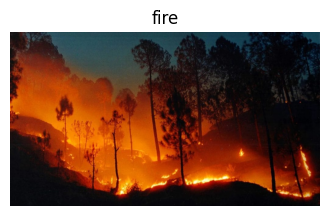

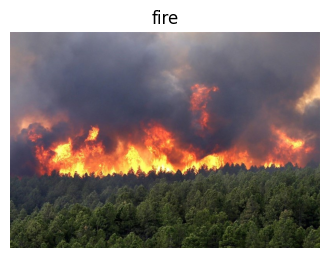

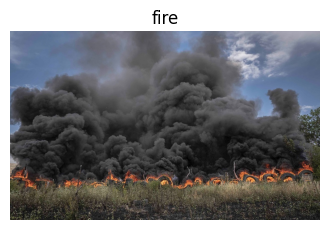

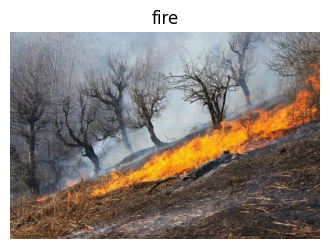

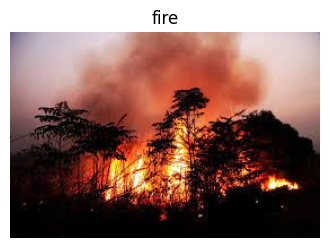

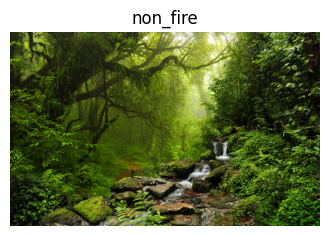

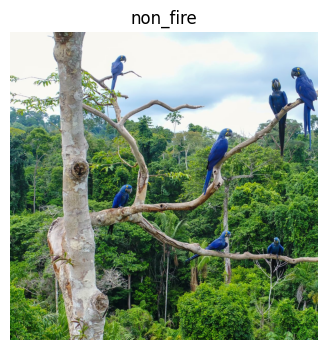

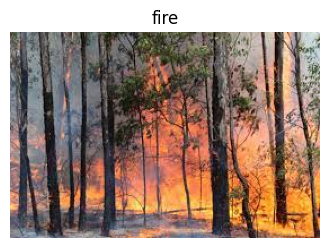

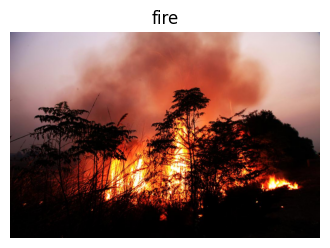

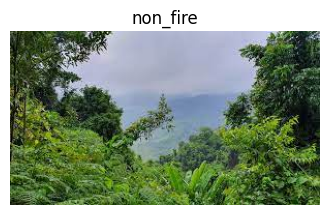

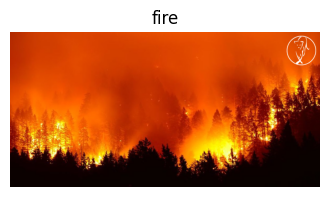

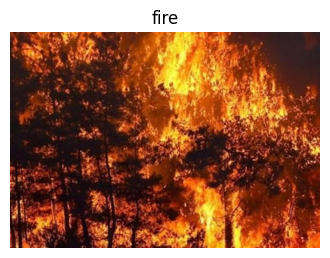

In [26]:
clf = load(MODEL_FILE)

test_files = sorted(glob.glob(os.path.join(TEST_DIR, "*")))
if not test_files:
    print(f"No images found in '{TEST_DIR}' folder.")

for address in test_files:
    img = cv2.imread(address)
    if img is None:
        continue

    pre = clf.predict(np.array([preprocess(img)]))[0]

    plt.figure(figsize=(4, 4))
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.title(str(pre))
    plt.axis("off")
    plt.show()